# 04 · LoRA (config C) e placar das cinco configurações

Guiding Hand · Generative AI for Engineering

**Especialização escolhida: LoRA.** O mesmo Qwen2.5-1.5B foi ajustado (QLoRA 4-bit) com 136 exemplos para aprender três comportamentos: devolver **JSON válido**, **citar a fonte do trecho certo** e **recusar** quando os trechos não respondem.

Cuidados contra contaminação do teste:
- nenhuma pergunta de treino é igual a uma de teste (conferido em `gerar_dados_treino.py`);
- **8 trechos ficaram fora do treino** (nem como resposta, nem como contexto), para separar *aprendeu o comportamento* de *decorou a base*.

Antes de rodar: `python src/gerar_dados_treino.py` e `python src/treinar_lora.py` (feche o notebook 03 antes, ele ocupa a GPU).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import numpy as np, pandas as pd, torch, time
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 70)
from config import CASOS, RESULTADOS, RAIZ, carregar_limiar
from busca import Buscador, carregar_trechos
from geracao import LLM, responder_rag
from avaliacao import placar

LIMIAR = carregar_limiar()
trechos = carregar_trechos()
casos = [json.loads(l) for l in open(CASOS, encoding='utf-8')]
buscador = Buscador(trechos)
ADAPTADOR = RAIZ / 'modelo-lora'
assert ADAPTADOR.exists(), 'Rode antes: python src/treinar_lora.py'
llm = LLM(adaptador=str(ADAPTADOR))
print('limiar =', LIMIAR, '| VRAM (GB):', round(torch.cuda.memory_allocated() / 1e9, 2))

W1110 22:45:07.600000 31816 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1110 22:45:11.847000 31816 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

limiar = 0.8754 | VRAM (GB): 3.1


## 1. Treino: curva de perda e custo

exemplos: 136 | épocas: 3 | batch efetivo: 4 | lr: 0.0002
LoRA: r=8, alpha=16 | nf4 4-bit (QLoRA)
tempo: 626s | VRAM pico: 1.71 GB
perda média por época: [0.0328, 0.0031, 0.0013]
trechos fora do treino: ['T03', 'T09', 'T10', 'T12', 'T16', 'T20', 'T28', 'T31']


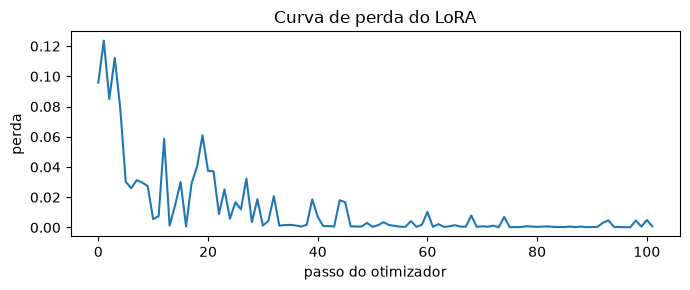

In [2]:
log = json.loads((RESULTADOS / 'treino_log.json').read_text(encoding='utf-8'))
print(f"exemplos: {log['n_exemplos']} | épocas: {log['epocas']} | batch efetivo: {log['batch_efetivo']} | lr: {log['lr']}")
print(f"LoRA: r={log['lora']['r']}, alpha={log['lora']['lora_alpha']} | {log['quantizacao']}")
print(f"tempo: {log['segundos']}s | VRAM pico: {log['vram_pico_gb']} GB")
print('perda média por época:', log['perda_por_epoca'])
print('trechos fora do treino:', log['trechos_fora_do_treino'])
import matplotlib.pyplot as plt
(RAIZ / 'avaliacao' / 'figuras').mkdir(exist_ok=True)
plt.figure(figsize=(7, 3)); plt.plot(log['perda_por_passo'])
plt.xlabel('passo do otimizador'); plt.ylabel('perda'); plt.title('Curva de perda do LoRA'); plt.tight_layout()
plt.savefig(RAIZ / 'avaliacao' / 'figuras' / 'loss_lora.png', dpi=150); plt.show()

## 2. Rodar a config C nos 35 casos

In [3]:
RESULTADOS.mkdir(exist_ok=True)
configs = {
    'C (RAG + LoRA + limiar)': lambda p: responder_rag(llm, buscador, p, limiar=LIMIAR),
    'C sem limiar': lambda p: responder_rag(llm, buscador, p, limiar=None),
}
novos = {}
for nome, fn in configs.items():
    t0 = time.time(); novos[nome] = {c['id']: fn(c['pergunta']) for c in casos}
    arq = RESULTADOS / (nome.split(' (')[0].replace(' ', '_') + '.json')
    arq.write_text(json.dumps(novos[nome], ensure_ascii=False, indent=1), encoding='utf-8')
    print(f'{nome}: {time.time() - t0:.0f}s -> {arq.name}')

C (RAG + LoRA + limiar): 253s -> C.json
C sem limiar: 305s -> C_sem_limiar.json


## 3. Placar das cinco configurações
A e B vêm do notebook 03 (arquivos em `avaliacao/resultados/`).

In [4]:
def carregar(arq): return json.loads((RESULTADOS / arq).read_text(encoding='utf-8'))
todos = {'A (sem contexto)': carregar('A.json'), 'B (RAG + limiar)': carregar('B.json'),
         'B sem limiar': carregar('B_sem_limiar.json'), **novos}
tab, detalhes = placar(todos, casos, trechos)
print(tab.T.to_string())
tab.to_csv(RAIZ / 'avaliacao' / 'placar.csv')

config                A (sem contexto) B (RAG + limiar) B sem limiar C (RAG + LoRA + limiar) C sem limiar
acerto (/27)                         7               19           20                      20           21
citação correta (/27)                0               21           22                      21           22
recusa correta (/8)                  2                8            5                       8            7
recusa indevida (/27)                0                1            0                       1            0
JSON válido (/35)                   33               34           34                      34           34
alucinação (/35)                    31                0            3                       0            1
taxa de alucinação                 89%               0%           9%                      0%           3%


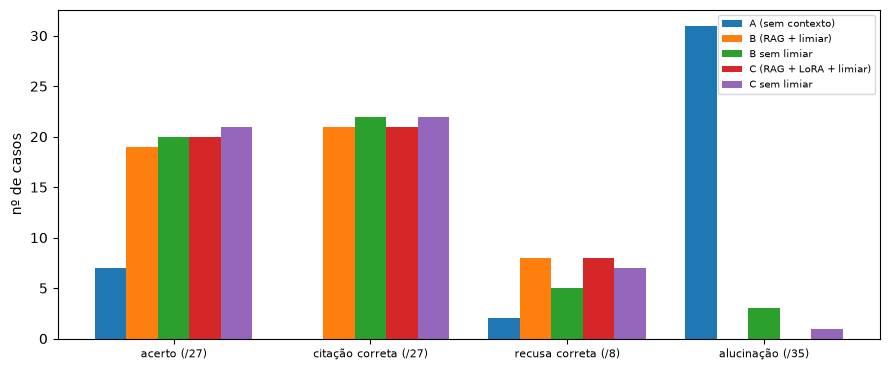

In [5]:
nomes = list(tab.columns[[0, 1, 2, 5]])
x = np.arange(len(nomes)); larg = 0.16
plt.figure(figsize=(9, 3.8))
for i, cfg in enumerate(tab.index):
    plt.bar(x + (i - 2) * larg, [tab.loc[cfg, n] for n in nomes], larg, label=cfg)
plt.xticks(x, nomes, fontsize=8); plt.ylabel('nº de casos'); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(RAIZ / 'avaliacao' / 'figuras' / 'placar.png', dpi=150); plt.show()

## 4. Aprendeu o comportamento ou decorou a base?
Separamos os casos de teste conforme o trecho esperado tenha sido **visto** ou **NÃO visto** no treino. Se o C só melhora nos vistos, é decoreba; se melhora nos dois, aprendeu o comportamento.

In [6]:
fora = set(log['trechos_fora_do_treino'])
grupo = {c['id']: ('NAO visto' if c['trecho_esperado'] in fora else 'visto') for c in casos if c['tipo'] == 'resposta'}
print('casos com resposta -> visto:', sum(v == 'visto' for v in grupo.values()), '| NAO visto:', sum(v == 'NAO visto' for v in grupo.values()))
linhas = []
for nome, det in detalhes.items():
    d = det[det.tipo == 'resposta'].copy(); d['grupo'] = d.id.map(grupo)
    for g, sub in d.groupby('grupo'):
        linhas.append({'config': nome, 'grupo': g, 'acerto': int(sub.acerto.sum()), 'citação correta': int(sub.citacao_correta.sum())})
print(pd.DataFrame(linhas).pivot(index='config', columns='grupo', values=['acerto', 'citação correta']).to_string())

casos com resposta -> visto: 19 | NAO visto: 8
                           acerto       citação correta      
grupo                   NAO visto visto       NAO visto visto
config                                                       
A (sem contexto)                2     5               0     0
B (RAG + limiar)                5    14               7    14
B sem limiar                    5    15               7    15
C (RAG + LoRA + limiar)         7    13               6    15
C sem limiar                    7    14               6    16


## 5. Casos em que o C ainda errou

In [7]:
det = detalhes['C (RAG + LoRA + limiar)']
errados = det[((det.tipo == 'resposta') & ~(det.acerto & det.citacao_correta)) | ((det.tipo == 'nao_consta') & ~det.recusa_correta)]
for id_ in errados.id:
    c = next(x for x in casos if x['id'] == id_)
    r = todos['C (RAG + LoRA + limiar)'][id_]
    print(id_, c['tipo'], '|', c['pergunta'])
    print('   esperado:', c['fonte_esperada'] or 'nao_consta', '| trechos buscados:', r['trechos'], '| top1:', round(r['top_score'], 3))
    print('   saída:', (r['raw'] or str(r['saida']))[:300]); print()

Q02 resposta | O que significa acessibilidade segundo a Lei Brasileira de Inclusão?
   esperado: Lei 13.146/2015, art. 3º, I | trechos buscados: ['T17', 'T11', 'T21'] | top1: 0.902
   saída: {"resposta":"A acessibilidade é direito que garante à pessoa com deficiência ou com mobilidade reduzida viver de forma independente e exercer seus direitos de cidadania e de participação social.","fonte":"Lei 13.146/2015, art. 53","status":"ok"}

Q04 resposta | O que são barreiras urbanísticas?
   esperado: Lei 13.146/2015, art. 3º, IV, a e c | trechos buscados: ['T04', 'T27', 'T28'] | top1: 0.848
   saída: {'resposta': 'Não consta na base de conhecimento.', 'fonte': None, 'status': 'nao_consta'}

Q05 resposta | Recusar uma adaptação razoável conta como discriminação?
   esperado: Lei 13.146/2015, art. 4º, caput e § 1º | trechos buscados: ['T05', 'T22', 'T11'] | top1: 0.884
   saída: {"resposta":"Praticar, induzir ou incitar discriminação de pessoa em razão de sua deficiência: Pena – reclusão, de 1

## 6. Interpretação 

O LoRA v1 praticamente empatou com o RAG simples quando o limiar está ligado (acerto 20 × 19, citação 21 × 21), diferença de um caso, sem valor conclusivo. O ganho aparece sem o limiar: o modelo ajustado recusou 7 dos 8 casos sem resposta contra 5 do B, e alucinou 1 vez contra 3. Isso indica que ele aprendeu o comportamento de recusa. A perda caiu a quase zero, sinal de que o modelo decorou os alvos. A análise do caso Q12 mostrou uma falha no desenho do treino: o alvo era um resumo que copiava o início do trecho e perdia o dado pedido, o que motivou o v2.